本 notebook 是 [M04.7 模型评价与解释](../notes/07-evaluation-interpretation.qmd) 的实例讲解。

1. 1. 回归指标、尾部与分组权重
2. 2. 排序、阈值与成本
3. 3. 嵌套选择与完整 Pipeline
4. 4. 概率校准与排序的区别
5. 5. 置换重要性与精确 Shapley 分解

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
from itertools import combinations
from math import factorial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.special import expit
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    log_loss,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from semiai.plotting import BLUE, GRAY, ORANGE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. 回归指标、尾部与分组权重

比较整体误差与按组平均误差，让指标权重从数据分布中显式浮现。

In [2]:
groups = np.repeat(["large", "small"], [900, 100])
truth = rng.normal(size=1000)
prediction = truth + rng.normal(size=1000) * np.where(groups == "large", 0.2, 1.0)
print(
    "MAE",
    mean_absolute_error(truth, prediction),
    "RMSE",
    np.sqrt(mean_squared_error(truth, prediction)),
    "R²",
    r2_score(truth, prediction),
)
table = pd.DataFrame({"group": groups, "squared_error": (truth - prediction) ** 2})
print(
    "按行 MSE:",
    table.squared_error.mean(),
    "各组 MSE:\n",
    table.groupby("group").squared_error.mean(),
)
print("等组加权 MSE:", table.groupby("group").squared_error.mean().mean())

MAE 0.22493139591842998 RMSE 0.3729502680890637 R² 0.8577169586930812
按行 MSE: 0.13909190246770445 各组 MSE:
 group
large    0.041472
small    1.017671
Name: squared_error, dtype: float64
等组加权 MSE: 0.5295713672343666


读法：按行平均把更多权重给大组，等组平均回答随机选一个组时的表现；两者都可以合理，但不能在比较模型时悄悄切换。

## 2. 排序、阈值与成本

生成稀有正类的概率分数，比较两个阈值的混淆矩阵以及不依赖固定阈值的排名指标。

In [3]:
x = rng.normal(size=6000)
probability = expit(2 * x - 4)
labels = rng.binomial(1, probability)
for threshold in [0.1, 0.5]:
    predicted = probability >= threshold
    print(
        "threshold",
        threshold,
        "confusion\n",
        confusion_matrix(labels, predicted),
        "precision",
        precision_score(labels, predicted),
        "recall",
        recall_score(labels, predicted),
    )
print(
    "positive rate",
    labels.mean(),
    "ROC AUC",
    roc_auc_score(labels, probability),
    "AP",
    average_precision_score(labels, probability),
)

threshold 0.1 confusion
 [[4791  795]
 [ 110  304]] precision 0.27661510464058237 recall 0.7342995169082126
threshold 0.5 confusion
 [[5535   51]
 [ 327   87]] precision 0.6304347826086957 recall 0.21014492753623187
positive rate 0.069 ROC AUC 0.8851895957976376 AP 0.4398100677560158


读法：阈值变化改变漏报与误报，AUC 不会告诉你采用哪个操作点；概率若校准，成本比可给决策阈值，但仍需按部署成本和容量验证。

## 3. 嵌套选择与完整 Pipeline

外层只评估整条内层选择流程，缩放在各训练折内部拟合，输出每折选择与外层损失。

In [4]:
X = rng.normal(size=(180, 12))
y = X[:, :3] @ np.array([2.0, -1.0, 0.5]) + rng.normal(0, 0.8, len(X))
outer = KFold(3, shuffle=True, random_state=42)
rows = []
for fold, (train, test) in enumerate(outer.split(X)):
    search = GridSearchCV(
        make_pipeline(StandardScaler(), Ridge()),
        {"ridge__alpha": [0.01, 1.0, 100.0]},
        cv=KFold(3, shuffle=True, random_state=7),
        scoring="neg_mean_squared_error",
    )
    search.fit(X[train], y[train])
    baseline = DummyRegressor().fit(X[train], y[train])
    rows.append(
        [
            fold,
            search.best_params_["ridge__alpha"],
            -search.best_score_,
            mean_squared_error(y[test], search.predict(X[test])),
            mean_squared_error(y[test], baseline.predict(X[test])),
        ]
    )
print(
    pd.DataFrame(
        rows, columns=["outer fold", "chosen alpha", "inner MSE", "outer MSE", "mean baseline MSE"]
    )
)

   outer fold  chosen alpha  inner MSE  outer MSE  mean baseline MSE
0           0          1.00   0.932006   0.630357           4.049604
1           1          1.00   0.803963   0.644601           5.192544
2           2          0.01   0.746134   0.700821           4.756578


读法：外层误差评价的是带选择的算法；三个外层折共享部分训练数据，不能把折分数当三个完全独立实验直接套标准误。

## 4. 概率校准与排序的区别

故意把真实 logit 放大三倍制造过度自信，独立校准集拟合 sigmoid 映射，再在新数据上比较 proper scores。

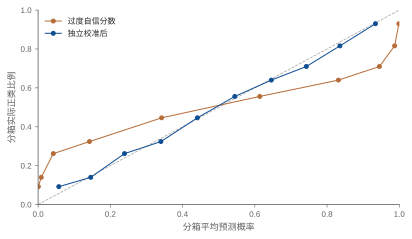

raw Brier 0.20081042021567702 NLL 0.7358963251350814 AUC 0.8148797516611089
calibrated Brier 0.17569554031351667 NLL 0.5261983575340329 AUC 0.8148797516611089
校准斜率和截距: [[0.36426531]] [0.00628351]


In [5]:
local = np.random.default_rng(23)
cal_logit = local.normal(0, 1.5, 2500)
cal_y = local.binomial(1, expit(cal_logit))
test_logit = local.normal(0, 1.5, 5000)
test_y = local.binomial(1, expit(test_logit))
calibrator = LogisticRegression(C=1e6).fit((3 * cal_logit)[:, None], cal_y)
raw = expit(3 * test_logit)
calibrated = calibrator.predict_proba((3 * test_logit)[:, None])[:, 1]
fig, ax = plt.subplots(figsize=(5.8, 3.4))
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=0.8)
for p, color, name in [(raw, ORANGE, "过度自信分数"), (calibrated, BLUE, "独立校准后")]:
    fraction, mean = calibration_curve(test_y, p, n_bins=10, strategy="quantile")
    ax.plot(mean, fraction, "o-", color=color, label=name, ms=4, lw=1)
ax.set(xlabel="分箱平均预测概率", ylabel="分箱实际正类比例", xlim=(0, 1), ylim=(0, 1))
ax.legend()
fig.tight_layout()
plt.show()

for name, p in [("raw", raw), ("calibrated", calibrated)]:
    print(
        name,
        "Brier",
        brier_score_loss(test_y, p),
        "NLL",
        log_loss(test_y, p),
        "AUC",
        roc_auc_score(test_y, p),
    )
print("校准斜率和截距:", calibrator.coef_, calibrator.intercept_)
assert np.isclose(roc_auc_score(test_y, raw), roc_auc_score(test_y, calibrated))

读法：单调映射保持排序，因此 AUC 可以相同而概率质量不同；可靠性曲线分箱有波动，Brier 与 log loss 评价的不只是纯校准误差。

## 5. 置换重要性与精确 Shapley 分解

在已知模型上计算留出集置换重要性，再枚举三特征子集，核验固定零基线下 Shapley 值的局部可加性。

In [6]:
X = rng.normal(size=(600, 3))
X[:, 1] = X[:, 0] + rng.normal(0, 0.02, len(X))
y = 2 * X[:, 0] + rng.normal(0, 0.2, len(X))
model = RandomForestRegressor(n_estimators=80, min_samples_leaf=4, random_state=42).fit(
    X[:400], y[:400]
)
importance = permutation_importance(model, X[400:], y[400:], n_repeats=8, random_state=42)
print("相关替代特征的置换重要性:", importance.importances_mean)
point = np.array([2.0, 3.0, 1.0])
d = 3


def value(subset):
    z = np.zeros(d)
    z[list(subset)] = point[list(subset)]
    return 1 + 2 * z[0] + z[1] + z[0] * z[2]


phi = np.zeros(d)
for j in range(d):
    others = [k for k in range(d) if k != j]
    for size in range(d):
        weight = factorial(size) * factorial(d - size - 1) / factorial(d)
        for subset in combinations(others, size):
            phi[j] += weight * (value((*subset, j)) - value(subset))
print("baseline:", value(()), "Shapley:", phi, "prediction:", value(tuple(range(d))))
assert np.isclose(value(()) + phi.sum(), value(tuple(range(d))))

相关替代特征的置换重要性: [7.16769028e-01 3.29529798e-01 5.64950060e-04]
baseline: 1.0 Shapley: [5. 3. 1.] prediction: 10.0


读法：这是固定零基线替换的有限博弈，不是条件期望 SHAP 或 TreeSHAP 实现；基线、缺失特征定义和相关结构改变解释，局部可加性不等于因果识别。

## 小结

指标定义价值取向，验证定义证据边界，校准定义概率语义，解释定义模型依赖。把它们放在明确的数据单位和选择流程下，才能让模型比较可复查，也让解释保持在数据实际支持的范围内。